# Glavni kod

In [17]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import HuberRegressor
from astropy.table import Table
import os
import time

### TNG API

In [18]:
headers = {
    "api-key": "56de1bf28cffd48ce85dc88d5ee2cae9"
}

### COSMOS

In [19]:
COSMOS_FILE = "asu.fit"

### Proto MW

In [20]:
protoMWmass = [
    10.68,
    10.48,
    10.28,
    9.98
]

protoMWsfr = [
    0.05189177782811362,
    0.21791328903439922,
    0.23471801067042988,
    0.24598888048212897
]

### TNG snapshotovi

In [21]:
snapshots = {
    99: 0,
    67: 1,
    50: 2,
    33: 3
}

### TNG uzorak

In [22]:
SAMPLE_FRAC = 0.3

### Folder za rezultate

In [23]:
output_folder = "MW_population_lists"

os.makedirs(
    output_folder,
    exist_ok=True
)

### COSMOS

In [24]:
print("ucitavanje cosmos podataka")

cos = Table.read(
    COSMOS_FILE,
    format="fits"
).to_pandas()


#cosmos filteri

cos = cos[
    (cos["zphot"] > 0) &
    (cos["zphot"] < 4) &
    (cos["MassMed"] > 0) &
    (cos["SFR"] > -5)
].copy()


#cosmos velicine

cos["logM"] = cos["MassMed"]
cos["logSFR"] = cos["SFR"]


#sfms filter

cos = cos[
    cos["logSFR"] > -3.5
].copy()


print(
    f"Broj COSMOS objekata nakon filtriranja: {len(cos)}"
)

ucitavanje cosmos podataka
Broj COSMOS objekata nakon filtriranja: 491874


### COSMOS redshift binovi

In [25]:
def get_cosmos_bin(z):

    if z == 0:

        return cos[
            (cos["zphot"] >= 0) &
            (cos["zphot"] < 0.5)
        ].copy()

    elif z == 1:

        return cos[
            (cos["zphot"] >= 0.5) &
            (cos["zphot"] < 1)
        ].copy()

    elif z == 2:

        return cos[
            (cos["zphot"] >= 1) &
            (cos["zphot"] < 2)
        ].copy()

    elif z == 3:

        return cos[
            (cos["zphot"] >= 2) &
            (cos["zphot"] < 4)
        ].copy()

### COSMOS SFMS

In [26]:
cosmos_fits = {}


for z in range(4):

    cos_sub = get_cosmos_bin(z)

    if len(cos_sub) < 2:

        print(
            f"Premalo COSMOS objekata za z={z}"
        )

        continue


    X = (
        cos_sub["logM"]
        .values
        .reshape(-1, 1)
    )

    y = cos_sub["logSFR"].values


    huber = HuberRegressor()

    huber.fit(
        X,
        y
    )


    cosmos_fits[z] = huber


    print(
        f"COSMOS SFMS fit z={z}: "
        f"slope = {huber.coef_[0]:.4f}, "
        f"intercept = {huber.intercept_:.4f}"
    )

COSMOS SFMS fit z=0: slope = 0.5831, intercept = -5.8443
COSMOS SFMS fit z=1: slope = 0.6110, intercept = -5.4837
COSMOS SFMS fit z=2: slope = 0.6587, intercept = -5.4334
COSMOS SFMS fit z=3: slope = 0.6004, intercept = -4.7110


### Ucitavanje, TNG

In [27]:
def load_snapshot(
        snap,
        z,
        max_pages=2000):

    url = (
        f"https://www.tng-project.org/api/TNG100-1/"
        f"snapshots/{snap}/subhalos/"
    )

    params = {
        "fields": "sfr,mass_log_msun"
    }

    all_chunks = []
    page = 0
    first = True


    while url is not None and page < max_pages:

        retries = 0


        #pokusaj ucitavanja stranice

        while retries < 5:

            try:

                if first:

                    r = requests.get(
                        url,
                        params=params,
                        headers=headers,
                        timeout=60
                    )

                    first = False

                else:

                    r = requests.get(
                        url,
                        headers=headers,
                        timeout=60
                    )


                #proverava i prvi i svaki sledeći request

                r.raise_for_status()

                break


            except Exception as e:

                retries += 1

                print(
                    f"\nSnapshot {snap}, "
                    f"z={z}, "
                    f"stranica {page + 1}: "
                    f"pokušaj {retries}/5 nije uspeo:"
                )

                print(e)


                if retries < 5:

                    time.sleep(
                        5 * retries
                    )


        #ako ne uspe ni pet pokusaja

        if retries == 5:

            print(
                f"\nSnapshot {snap}, z={z}: "
                f"5 neuspešnih pokušaja, odustaje i nastavlja dalje"
            )

            break


        #json

        data = r.json()


        #provera rezultata

        if (
            "results" not in data
            or len(data["results"]) == 0
        ):

            print(
                f"\nSnapshot {snap}, z={z}: "
                f"nema više rezultata."
            )

            break


        chunk = pd.DataFrame(
            data["results"]
        )


        #logM

        chunk["logM"] = (
            chunk["mass_log_msun"]
        )


        #logSFR

        chunk["logSFR"] = np.log10(
            np.clip(
                chunk["sfr"],
                1e-5,
                None
            )
        )


        #cuvanje stranice

        all_chunks.append(
            chunk
        )


        page += 1


        print(
            f"\rSnapshot {snap}, z={z}: "
            f"stranica {page}, "
            f"objekata = {len(chunk)}, "
            f"ukupno = "
            f"{sum(len(x) for x in all_chunks)}",
            end=""
        )


        #sledeca stranica

        url = data.get(
            "next",
            None
        )


        #kratka pauza

        time.sleep(0.5)


    print()


    #ako nema podataka

    if len(all_chunks) == 0:

        print(
            f"Nema podataka za snapshot {snap}"
        )

        return pd.DataFrame()


    #spajanje stranica

    df = pd.concat(
        all_chunks,
        ignore_index=True
    )


    #redshift

    df["z"] = z


    #random sample

    df = df.sample(
        frac=SAMPLE_FRAC,
        random_state=42
    )


    print(
        f"\nSnapshot {snap}, z={z}: "
        f"ukupno učitano = {page} stranica"
    )

    print(
        f"Nakon SAMPLE_FRAC={SAMPLE_FRAC}: "
        f"{len(df)} objekata"
    )


    return df

### SFR-weighted gas metallicity

In [28]:
def get_gasmetallicitysfrweighted(
        snap,
        subhalo_id,
        max_retries=5):

    url = (
        f"https://www.tng-project.org/api/TNG100-1/"
        f"snapshots/{snap}/subhalos/"
        f"{int(subhalo_id)}/"
    )

    for attempt in range(max_retries):

        try:

            r = requests.get(
                url,
                headers=headers,
                timeout=30
            )

            r.raise_for_status()

            data = r.json()

            if "gasmetallicitysfrweighted" in data:

                return data[
                    "gasmetallicitysfrweighted"
                ]

            else:

                print(
                    f"Nema gasmetallicitysfrweighted: "
                    f"snapshot={snap}, "
                    f"subhalo={subhalo_id}"
                )

                return np.nan

        except Exception as e:

            print(
                f"Greška za subhalo "
                f"{subhalo_id}, "
                f"pokušaj {attempt + 1}: "
                f"{e}"
            )

            time.sleep(
                2 * (attempt + 1)
            )

    return np.nan

### Rezultati MW like populacija

In [29]:
MW_population = {
    0: [],
    1: [],
    2: [],
    3: []
}


MW_statistics = {}

### TNG snapshots



SNAPSHOT 99  |  z ≈ 0
Snapshot 99, z=0: stranica 270, objekata = 100, ukupno = 27000
Snapshot 99, z=0, stranica 271: pokušaj 1/5 nije uspeo:
503 Server Error: Service Unavailable for url: https://www.tng-project.org/api/TNG100-1/snapshots/99/subhalos/?fields=sfr%2Cmass_log_msun&limit=100&offset=27000
Snapshot 99, z=0: stranica 2000, objekata = 100, ukupno = 200000

Snapshot 99, z=0: ukupno učitano = 2000 stranica
Nakon SAMPLE_FRAC=0.3: 60000 objekata
TNG SFMS objekata: 561
TNG SFMS fit z=0: slope = 0.1979, intercept = -2.9386
TNG upper: 472
TNG lower: 89
+++++++++++++++++++++
Broj objekata u masenom prozoru 0.2 dex 76
+++++++++++++++++++++

MW POPULACIJA
N = 76
median logSFR = -1.152
16–84% interval = [-1.513, -0.590]


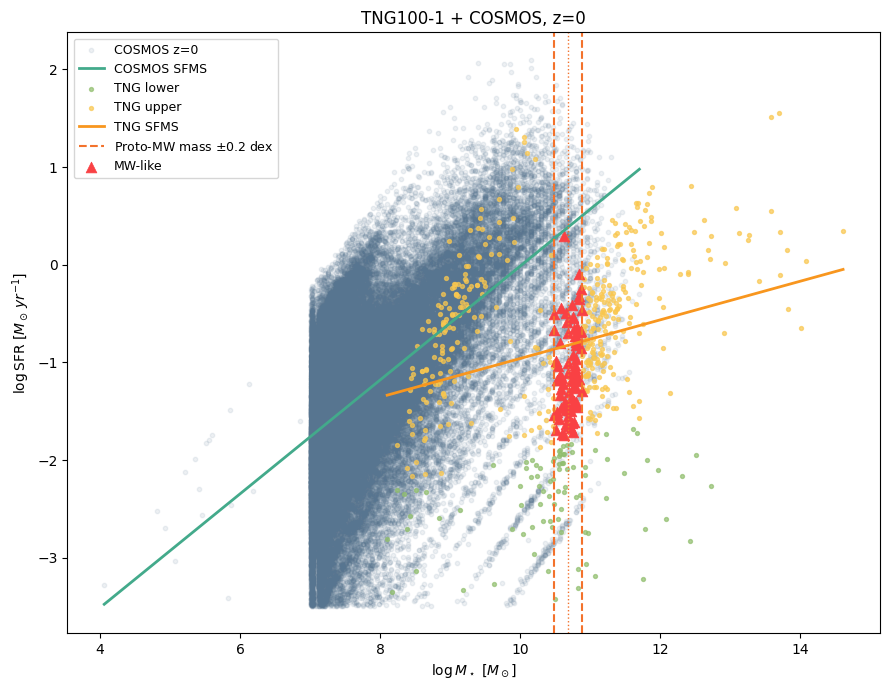


gasmetallicity za MW like objekte...


SNAPSHOT 67  |  z ≈ 1
Snapshot 67, z=1: stranica 422, objekata = 100, ukupno = 42200
Snapshot 67, z=1, stranica 423: pokušaj 1/5 nije uspeo:
503 Server Error: Service Unavailable for url: https://www.tng-project.org/api/TNG100-1/snapshots/67/subhalos/?fields=sfr%2Cmass_log_msun&limit=100&offset=42200

Snapshot 67, z=1, stranica 423: pokušaj 2/5 nije uspeo:
503 Server Error: Service Unavailable for url: https://www.tng-project.org/api/TNG100-1/snapshots/67/subhalos/?fields=sfr%2Cmass_log_msun&limit=100&offset=42200
Snapshot 67, z=1: stranica 1314, objekata = 100, ukupno = 131400
Snapshot 67, z=1, stranica 1315: pokušaj 1/5 nije uspeo:
503 Server Error: Service Unavailable for url: https://www.tng-project.org/api/TNG100-1/snapshots/67/subhalos/?fields=sfr%2Cmass_log_msun&limit=100&offset=131400

Snapshot 67, z=1, stranica 1315: pokušaj 2/5 nije uspeo:
503 Server Error: Service Unavailable for url: https://www.tng-project.org/api/TNG100-1/snapshots/

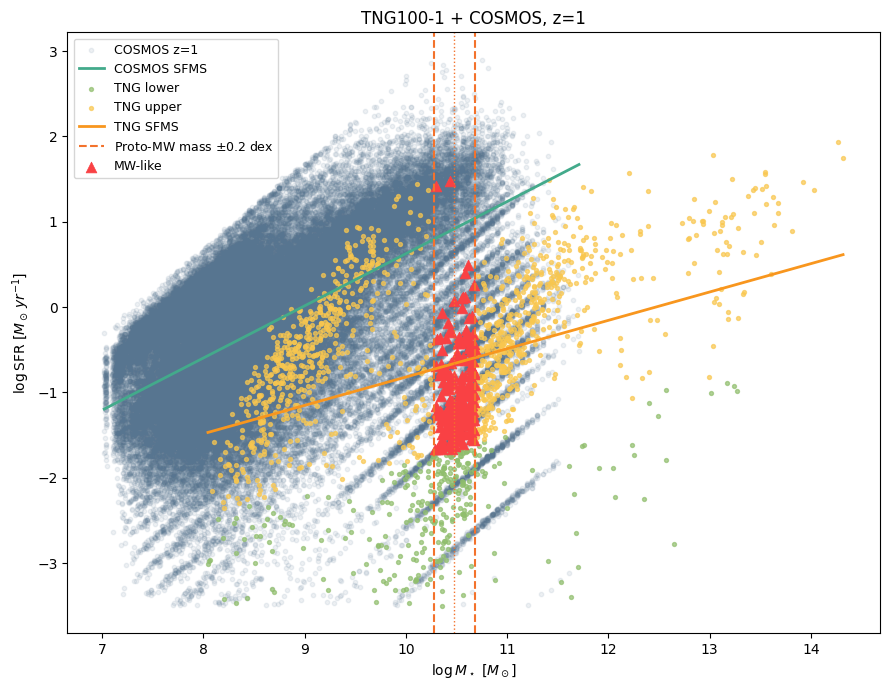


gasmetallicity za MW like objekte...


SNAPSHOT 50  |  z ≈ 2
Snapshot 50, z=2: stranica 1246, objekata = 100, ukupno = 124600
Snapshot 50, z=2, stranica 1247: pokušaj 1/5 nije uspeo:
503 Server Error: Service Unavailable for url: https://www.tng-project.org/api/TNG100-1/snapshots/50/subhalos/?fields=sfr%2Cmass_log_msun&limit=100&offset=124600
Snapshot 50, z=2: stranica 1320, objekata = 100, ukupno = 132000
Snapshot 50, z=2, stranica 1321: pokušaj 1/5 nije uspeo:
503 Server Error: Service Unavailable for url: https://www.tng-project.org/api/TNG100-1/snapshots/50/subhalos/?fields=sfr%2Cmass_log_msun&limit=100&offset=132000
Snapshot 50, z=2: stranica 1525, objekata = 100, ukupno = 152500
Snapshot 50, z=2, stranica 1526: pokušaj 1/5 nije uspeo:
503 Server Error: Service Unavailable for url: https://www.tng-project.org/api/TNG100-1/snapshots/50/subhalos/?fields=sfr%2Cmass_log_msun&limit=100&offset=152500

Snapshot 50, z=2, stranica 1526: pokušaj 2/5 nije uspeo:
503 Server Error: Service Un

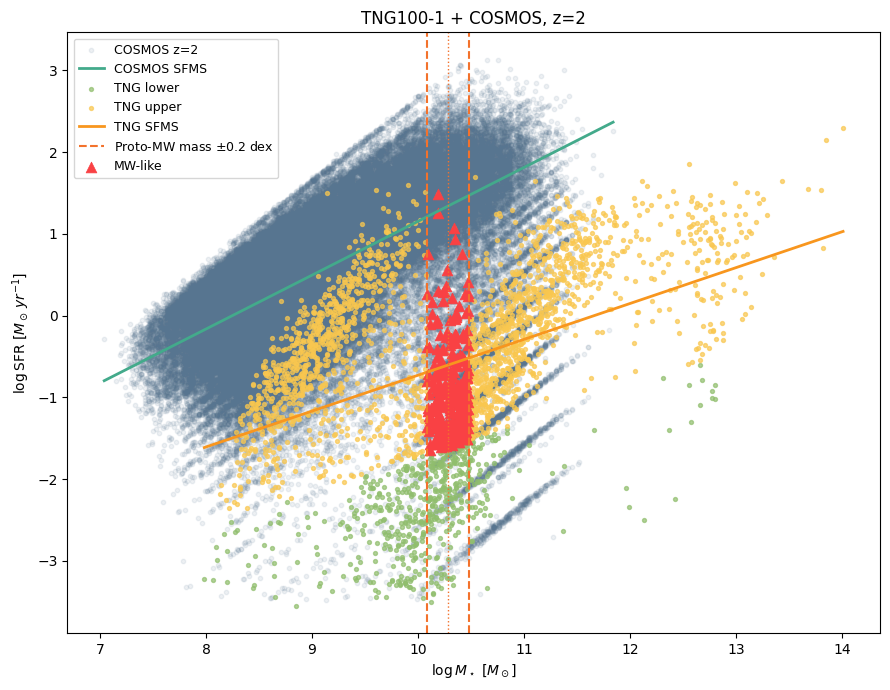


gasmetallicity za MW like objekte...


SNAPSHOT 33  |  z ≈ 3
Snapshot 33, z=3: stranica 223, objekata = 100, ukupno = 22300
Snapshot 33, z=3, stranica 224: pokušaj 1/5 nije uspeo:
503 Server Error: Service Unavailable for url: https://www.tng-project.org/api/TNG100-1/snapshots/33/subhalos/?fields=sfr%2Cmass_log_msun&limit=100&offset=22300
Snapshot 33, z=3: stranica 2000, objekata = 100, ukupno = 200000

Snapshot 33, z=3: ukupno učitano = 2000 stranica
Nakon SAMPLE_FRAC=0.3: 60000 objekata
TNG SFMS objekata: 6296
TNG SFMS fit z=3: slope = 1.1391, intercept = -12.5690
TNG upper: 5544
TNG lower: 752
+++++++++++++++++++++
Broj objekata u masenom prozoru 0.2 dex 1042
+++++++++++++++++++++

MW POPULACIJA
N = 1042
median logSFR = -1.293
16–84% interval = [-1.906, -0.470]


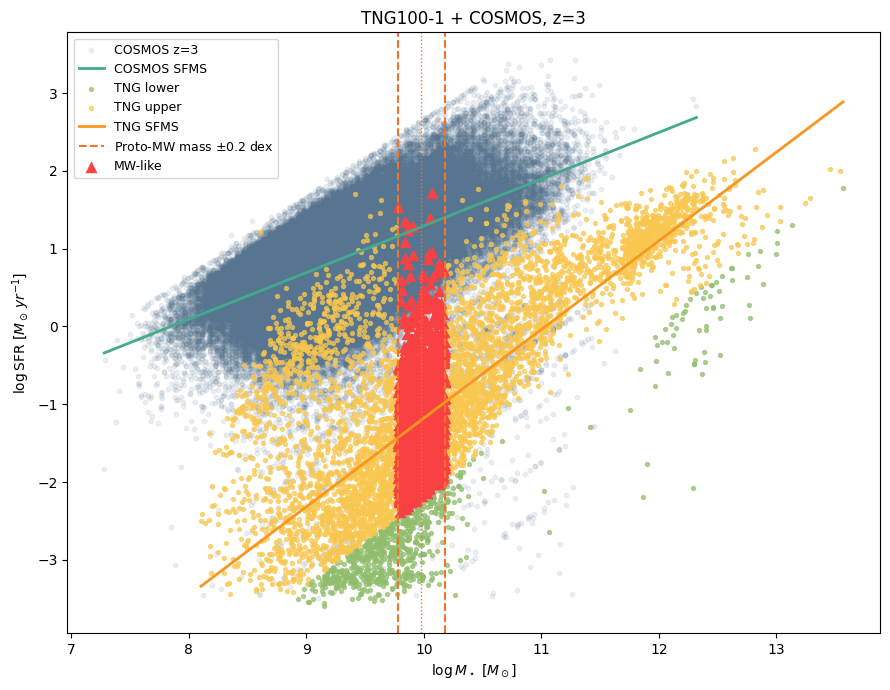


gasmetallicity za MW like objekte...


In [30]:
for snap, z in snapshots.items():

    print()
    print()
    print("=" * 70)
    print(
        f"SNAPSHOT {snap}  |  z ≈ {z}"
    )
    print("=" * 70)


    #ucitavanje snapshotova

    df = load_snapshot(
        snap,
        z
    )


    if len(df) == 0:

        print(
            "snapshot nije ucitan."
        )

        continue


    #tng sfms populacija
    #izbacuje logSFR<-4

    df_sfms = df[
        df["logSFR"] >= -4
    ].copy()


    print(
        f"TNG SFMS objekata: "
        f"{len(df_sfms)}"
    )


    #tng sfms hubber fit

    X = (
        df_sfms["logM"]
        .values
        .reshape(-1, 1)
    )

    y = df_sfms["logSFR"].values


    tng_huber = HuberRegressor()

    tng_huber.fit(
        X,
        y
    )


    print(
        f"TNG SFMS fit z={z}: "
        f"slope = {tng_huber.coef_[0]:.4f}, "
        f"intercept = {tng_huber.intercept_:.4f}"
    )


    #sfms predikcija

    df_sfms["SFMS_fit"] = (
        tng_huber.predict(X)
    )


    #odstupanje od tng sfms

    df_sfms["delta_logSFR"] = (
        df_sfms["logSFR"]
        - df_sfms["SFMS_fit"]
    )


    #upper i lower populacija
    # upper: delta_logSFR>-1
    # lower: delta_logSFR<=-1

    upper = df_sfms[
        df_sfms["delta_logSFR"] > -1.0
    ].copy()


    lower = df_sfms[
        df_sfms["delta_logSFR"] <= -1.0
    ].copy()


    print(
        f"TNG upper: {len(upper)}"
    )

    print(
        f"TNG lower: {len(lower)}"
    )


    #mw maseni opseg
    #|logM-logM_MW|<=0.2

    mw_mass_like = upper[
        np.abs(
            upper["logM"]
            - protoMWmass[z]
        ) <= 0.2
    ].copy()


    #mw populacija
    #upper i MW mass range

    N = len(
        mw_mass_like
    )

    print("+++++++++++++++++++++")
    print("Broj objekata u masenom prozoru 0.2 dex",N)
    print("+++++++++++++++++++++")

    #statistika

    if N > 0:

        mw_logSFR = (
            mw_mass_like["logSFR"]
            .values
        )


        median_logSFR = np.median(
            mw_logSFR
        )


        p16 = np.percentile(
            mw_logSFR,
            16
        )


        p84 = np.percentile(
            mw_logSFR,
            84
        )


    else:

        median_logSFR = np.nan

        p16 = np.nan

        p84 = np.nan


    MW_statistics[z] = {

        "N": N,

        "median_logSFR":
            median_logSFR,

        "p16_logSFR":
            p16,

        "p84_logSFR":
            p84
    }


    #ispis statistike za snapshot

    print()
    print(
        "MW POPULACIJA"
    )

    print(
        f"N = {N}"
    )

    print(
        f"median logSFR = "
        f"{median_logSFR:.3f}"
    )

    print(
        f"16–84% interval = "
        f"[{p16:.3f}, {p84:.3f}]"
    )


    #grafik

    plt.figure(
        figsize=(9, 7)
    )


    #cosmos

    cos_sub = get_cosmos_bin(z)


    plt.scatter(
        cos_sub["logM"],
        cos_sub["logSFR"],
        s=10,
        alpha=0.1,
        label=f"COSMOS z={z}",
        color='#577590'
    )


    #cosmos sfms

    if z in cosmos_fits:

        cos_fit = cosmos_fits[z]

        x_cos = np.linspace(
            cos_sub["logM"].min(),
            cos_sub["logM"].max(),
            200
        )


        y_cos = cos_fit.predict(
            x_cos.reshape(-1, 1)
        )


        plt.plot(
            x_cos,
            y_cos,
            linestyle="-",
            linewidth=2,
            label="COSMOS SFMS",
            c='#43aa8b'
        )


    #tng lower

    plt.scatter(
        lower["logM"],
        lower["logSFR"],
        s=8,
        alpha=0.7,
        color="#90be6d",
        label="TNG lower"
    )


    #tng upper

    plt.scatter(
        upper["logM"],
        upper["logSFR"],
        s=8,
        alpha=0.7,
        color="#f9c74f",
        label="TNG upper"
    )


    #tng sfms

    x_tng = np.linspace(
        df_sfms["logM"].min(),
        df_sfms["logM"].max(),
        200
    )


    y_tng = tng_huber.predict(
        x_tng.reshape(-1, 1)
    )


    plt.plot(
        x_tng,
        y_tng,
        color="#f8961e",
        linestyle="-",
        linewidth=2,
        label="TNG SFMS"
    )


    #mw maseni opseg

    plt.axvline(
        protoMWmass[z] - 0.2,
        color="#f3722c",
        linestyle="--",
        linewidth=1.5
    )


    plt.axvline(
        protoMWmass[z] + 0.2,
        color="#f3722c",
        linestyle="--",
        linewidth=1.5,
        label=r"Proto-MW mass $\pm0.2$ dex"
    )


    #proto mw masa

    plt.axvline(
        protoMWmass[z],
        color="#f3722c",
        linestyle=":",
        linewidth=1
    )


    #mw like galaksije

    plt.scatter(
        mw_mass_like["logM"],
        mw_mass_like["logSFR"],
        marker="^",
        s=60,
        color="#f94144",
        linewidth=0.5,
        label="MW-like"
    )


    #ose

    plt.xlabel(
        r"$\log M_\star\ [M_\odot]$"
    )


    plt.ylabel(
        r"$\log \mathrm{SFR}\ "
        r"[M_\odot\,yr^{-1}]$"
    )


    plt.title(
        f"TNG100-1 + COSMOS, z={z}"
    )


    plt.legend(
        fontsize=9
    )


    plt.tight_layout()

    plt.show()


    #uzima metalicnost za mw like objekte

    print()
    print(
        "gasmetallicity "
        "za MW like objekte..."
    )


    for _, galaxy in (
        mw_mass_like.iterrows()
    ):

        subhalo_id = galaxy["id"]


        Z = get_gasmetallicitysfrweighted(
            snap,
            subhalo_id
            )


        '''CSV:
        logM
        logSFR
        Z=gasmetallicity'''

        MW_population[z].append({

            "logM":
                galaxy["logM"],

            "logSFR":
                galaxy["logSFR"],

            "Z":
                Z
        })


        time.sleep(
            0.1
        )

### Ukupan broj objekata

In [31]:
import requests

API_KEY = "56de1bf28cffd48ce85dc88d5ee2cae9"

snapshots = {
    99: 0,
    67: 1,
    50: 2,
    33: 3
}

BASE_URL = "https://www.tng-project.org/api/TNG100-1/snapshots/"

for snap, z in snapshots.items():

    url = f"{BASE_URL}{snap}/"

    response = requests.get(
        url,
        headers={"api-key": API_KEY.strip()},
        timeout=30
    )

    print("\n" + "=" * 60)
    print(f"SNAPSHOT {snap} | Očekivani redshift: z ≈ {z}")
    print("=" * 60)
    print("Status:", response.status_code)

    if response.status_code == 200:
        data = response.json()

        print(f"Stvarni redshift: {data['redshift']:.4f}")
        print(f"Gasne ćelije: {data['num_gas']:,}")
        print(f"Čestice tamne materije: {data['num_dm']:,}")
        print(f"Zvezdane čestice: {data['num_stars']:,}")
        print(f"Crne rupe: {data['num_bhs']:,}")
        print(f"FoF grupe: {data['num_groups_fof']:,}")
        print(f"Subfind subhaloi: {data['num_groups_subfind']:,}")
    else:
        print("Odgovor servera:", response.text[:500])


SNAPSHOT 99 | Očekivani redshift: z ≈ 0
Status: 200
Stvarni redshift: 0.0000
Gasne ćelije: 5,453,610,043
Čestice tamne materije: 6,028,568,000
Zvezdane čestice: 453,723,346
Crne rupe: 37,053
FoF grupe: 6,291,349
Subfind subhaloi: 4,371,211

SNAPSHOT 67 | Očekivani redshift: z ≈ 1
Status: 200
Stvarni redshift: 0.5030
Gasne ćelije: 5,532,948,598
Čestice tamne materije: 6,028,568,000
Zvezdane čestice: 367,811,595
Crne rupe: 37,067
FoF grupe: 6,572,201
Subfind subhaloi: 4,765,222

SNAPSHOT 50 | Očekivani redshift: z ≈ 2
Status: 200
Stvarni redshift: 0.9973
Gasne ćelije: 5,604,027,289
Čestice tamne materije: 6,028,568,000
Zvezdane čestice: 279,081,778
Crne rupe: 35,557
FoF grupe: 6,736,881
Subfind subhaloi: 5,127,294

SNAPSHOT 33 | Očekivani redshift: z ≈ 3
Status: 200
Stvarni redshift: 2.0020
Gasne ćelije: 5,708,627,539
Čestice tamne materije: 6,028,568,000
Zvezdane čestice: 143,951,082
Crne rupe: 29,440
FoF grupe: 6,864,573
Subfind subhaloi: 5,621,338


### Liste

In [32]:
'''
print()
print()
print("cuvanje mw populacija")


for z in range(4):


    df_output = pd.DataFrame(
        MW_population[z]
    )


    filename = os.path.join(
        output_folder,
        f"MW_population_z{z}weighted.csv"
    )


    df_output.to_csv(
        filename,
        index=False
    )


    print()
    print(
        f"z={z}: "
        f"{len(df_output)} objekata"
    )

    print(
        f"Sačuvano: {filename}"
    )


    if len(df_output) > 0:

        print(
            df_output.head()
        )
'''

'\nprint()\nprint()\nprint("cuvanje mw populacija")\n\n\nfor z in range(4):\n\n\n    df_output = pd.DataFrame(\n        MW_population[z]\n    )\n\n\n    filename = os.path.join(\n        output_folder,\n        f"MW_population_z{z}weighted.csv"\n    )\n\n\n    df_output.to_csv(\n        filename,\n        index=False\n    )\n\n\n    print()\n    print(\n        f"z={z}: "\n        f"{len(df_output)} objekata"\n    )\n\n    print(\n        f"Sačuvano: {filename}"\n    )\n\n\n    if len(df_output) > 0:\n\n        print(\n            df_output.head()\n        )\n'

### Statistika

In [33]:
print()
print()
print("statistika mw populacija")


for z in range(4):


    stats = MW_statistics.get(z)


    if stats is None:

        continue


    print()

    print(
        f"z = {z}"
    )

    print(
        f"N = {stats['N']}"
    )

    print(
        f"median logSFR = "
        f"{stats['median_logSFR']:.3f}"
    )

    print(
        f"16–84% interval = "
        f"[{stats['p16_logSFR']:.3f}, "
        f"{stats['p84_logSFR']:.3f}]"
    )



statistika mw populacija

z = 0
N = 76
median logSFR = -1.152
16–84% interval = [-1.513, -0.590]

z = 1
N = 208
median logSFR = -1.183
16–84% interval = [-1.481, -0.498]

z = 2
N = 268
median logSFR = -1.037
16–84% interval = [-1.416, -0.338]

z = 3
N = 1042
median logSFR = -1.293
16–84% interval = [-1.906, -0.470]


# 3D SFR weighted 


z = 0
Ukupan broj MW-like objekata = 76
Broj objekata u gornjih 10% = 8

max-Np objekat
logM       = 10.7517
logSFR     = -1.7153
Z          = 1.860360e-02
Np         = 3.078144e+21

gornjih 10% po Np
min(Np)    = 1.656579e+21
max(Np)    = 3.078144e+21
median(Np) = 2.262575e+21

statistika
min(Np)    = 9.519e+18
max(Np)    = 3.078e+21
median(Np) = 4.258e+20


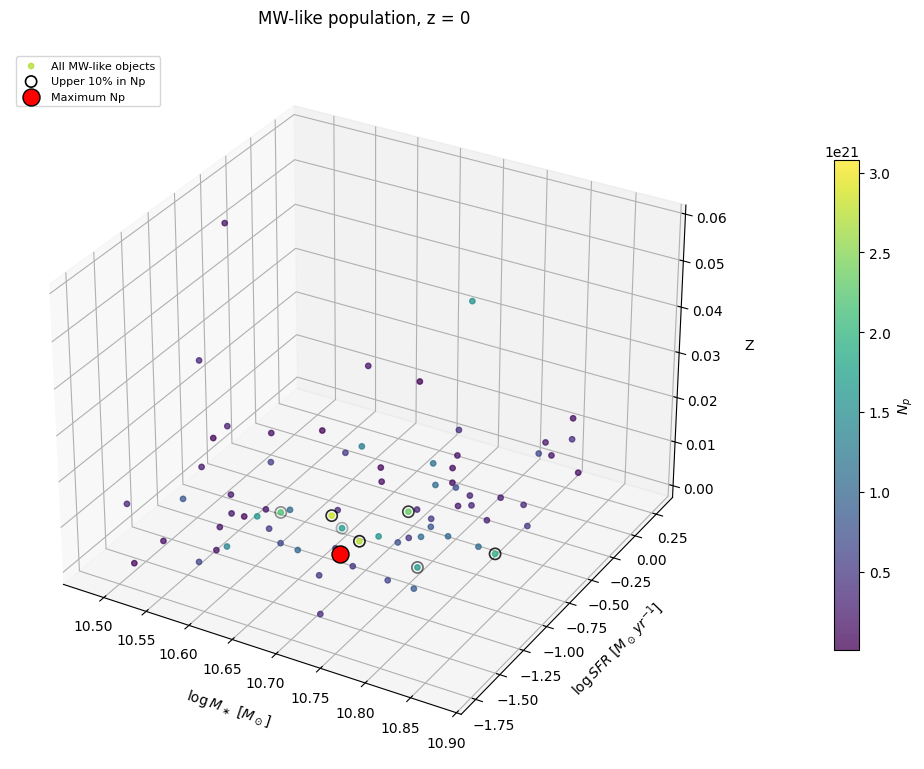


z = 1
Ukupan broj MW-like objekata = 208
Broj objekata u gornjih 10% = 21

max-Np objekat
logM       = 10.4879
logSFR     = -1.5603
Z          = 4.230130e-02
Np         = 1.453695e+21

gornjih 10% po Np
min(Np)    = 5.672162e+20
max(Np)    = 1.453695e+21
median(Np) = 8.137858e+20

statistika
min(Np)    = 6.349e+17
max(Np)    = 1.454e+21
median(Np) = 1.583e+20


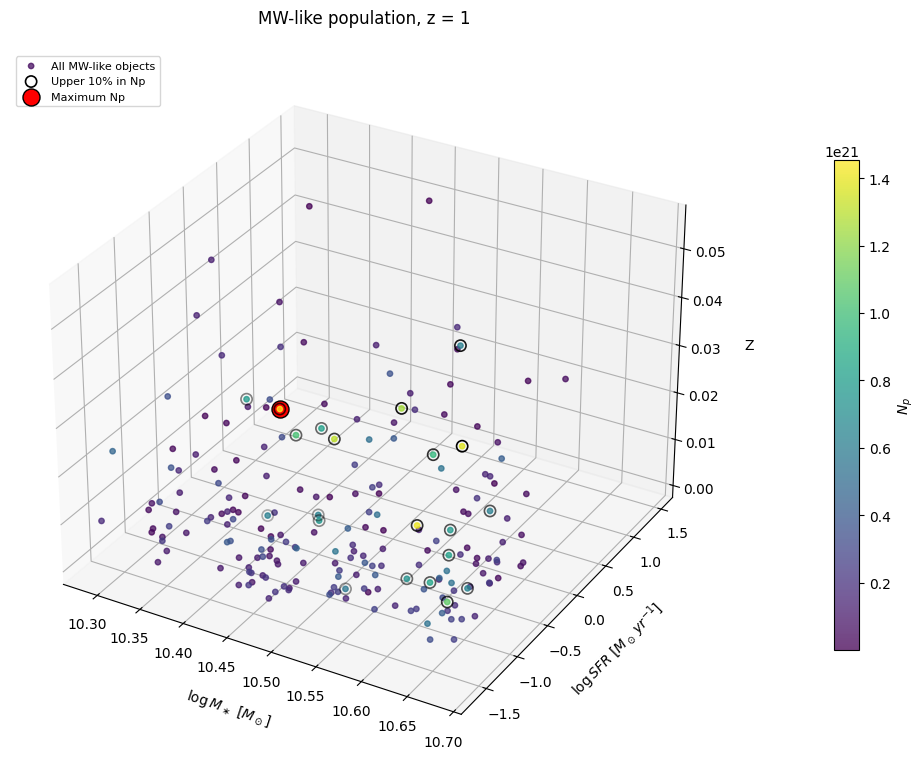


z = 2
Ukupan broj MW-like objekata = 268
Broj objekata u gornjih 10% = 27

max-Np objekat
logM       = 10.3321
logSFR     = -1.4210
Z          = 5.191090e-02
Np         = 6.317611e+20

gornjih 10% po Np
min(Np)    = 1.501993e+20
max(Np)    = 6.317611e+20
median(Np) = 2.304052e+20

statistika
min(Np)    = 4.412e+17
max(Np)    = 6.318e+20
median(Np) = 3.751e+19


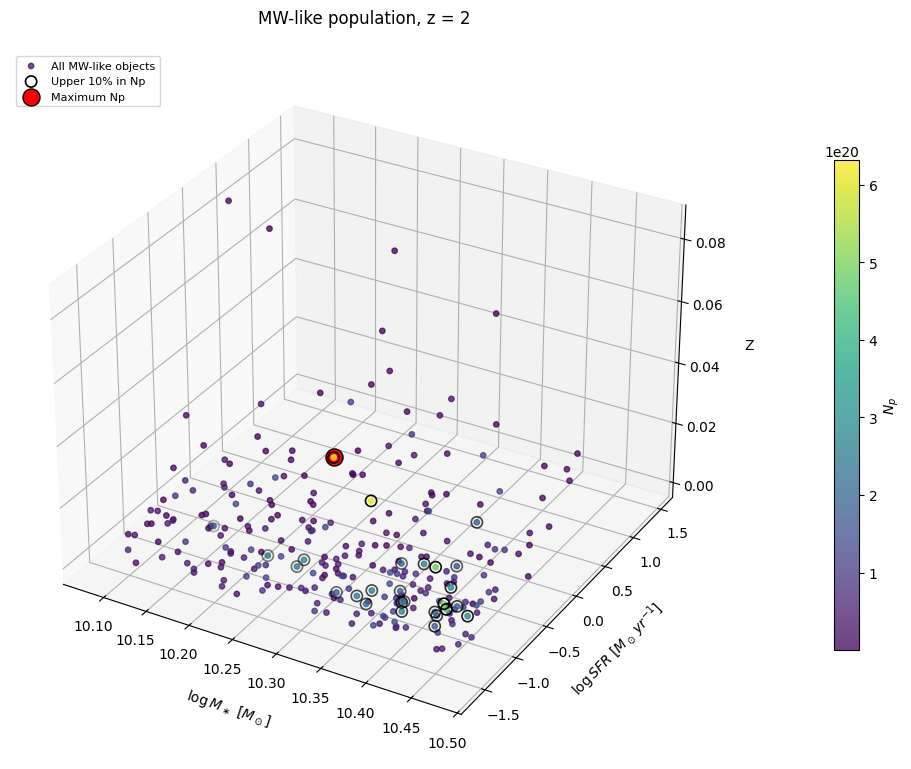


z = 3
Ukupan broj MW-like objekata = 1042
Broj objekata u gornjih 10% = 105

max-Np objekat
logM       = 10.1467
logSFR     = -1.9703
Z          = 1.955450e-02
Np         = 3.589161e+20

gornjih 10% po Np
min(Np)    = 3.081249e+19
max(Np)    = 3.589161e+20
median(Np) = 4.230089e+19

statistika
min(Np)    = 3.721e+16
max(Np)    = 3.589e+20
median(Np) = 6.050e+18


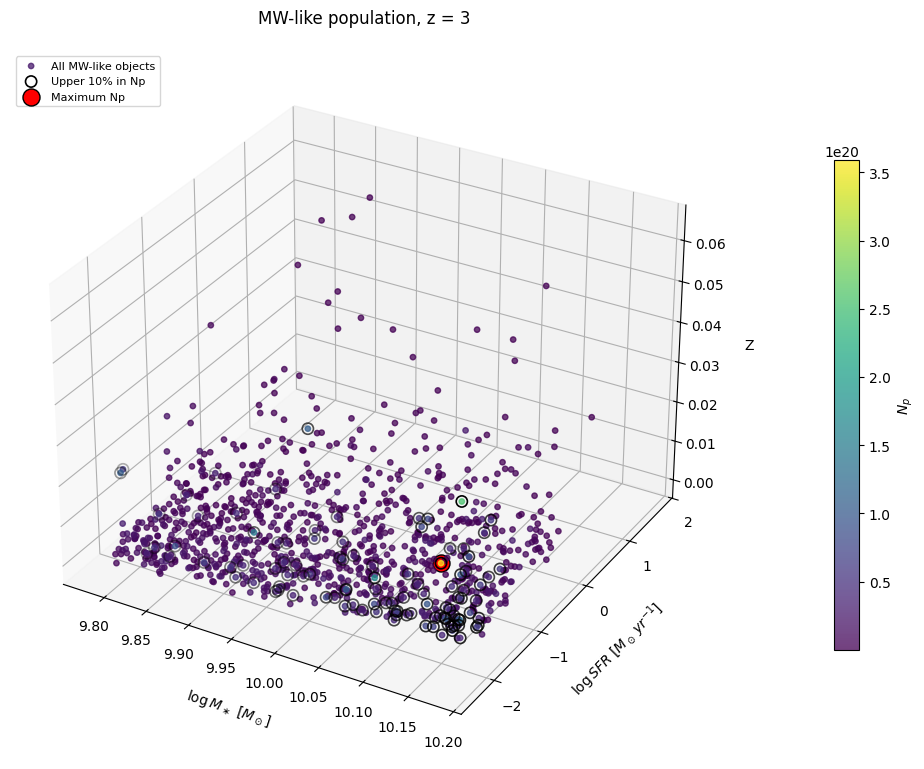

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

#parametar alpha
alpha = 1.0

#za svaki redshift
for z in range(4):

    #ucitavanje podataka
    df = pd.read_csv(f"MW_population_z{z}weighted.csv")

    #masa
    logM = df["logM"].values
    M = 10**logM

    #SFR
    logSFR = df["logSFR"].values
    SFR = 10**logSFR

    #metalicnost
    Z = df["Z"].values

    #Np
    Np = M**2 * Z**alpha / SFR

    #maksimalni Np objekat
    max_index = np.argmax(Np)

    max_Np = Np[max_index]
    max_logM = logM[max_index]
    max_logSFR = logSFR[max_index]
    max_Z = Z[max_index]

    #gornjih 10% objekata po Np
    N = len(df)
    n_top10 = max(1, int(np.ceil(0.10 * N)))

    top10_indices = np.argsort(Np)[-n_top10:]

    top10_logM = logM[top10_indices]
    top10_logSFR = logSFR[top10_indices]
    top10_Z = Z[top10_indices]
    top10_Np = Np[top10_indices]

    #statistika
    print()
    print("=" * 60)
    print(f"z = {z}")
    print("=" * 60)
    print(f"Ukupan broj MW-like objekata = {N}")
    print(f"Broj objekata u gornjih 10% = {n_top10}")

    print("\nmax-Np objekat")
    print(f"logM       = {max_logM:.4f}")
    print(f"logSFR     = {max_logSFR:.4f}")
    print(f"Z          = {max_Z:.6e}")
    print(f"Np         = {max_Np:.6e}")

    print("\ngornjih 10% po Np")
    print(f"min(Np)    = {top10_Np.min():.6e}")
    print(f"max(Np)    = {top10_Np.max():.6e}")
    print(f"median(Np) = {np.median(top10_Np):.6e}")

    print("\nstatistika")
    print(f"min(Np)    = {Np.min():.3e}")
    print(f"max(Np)    = {Np.max():.3e}")
    print(f"median(Np) = {np.median(Np):.3e}")

    #3D grafik
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")

    #MW-like objekti
    scatter = ax.scatter(
        logM,
        logSFR,
        Z,
        c=Np,
        cmap="viridis",
        s=15,
        alpha=0.75,
        label="All MW-like objects"
    )

    #gornjih 10% po Np
    ax.scatter(
        top10_logM,
        top10_logSFR,
        top10_Z,
        s=65,
        facecolors="none",
        edgecolors="black",
        linewidths=1.2,
        label="Upper 10% in Np"
    )

    #objekat sa maksimalnim Np
    ax.scatter(
        [max_logM],
        [max_logSFR],
        [max_Z],
        s=150,
        c="red",
        edgecolors="black",
        linewidths=1.0,
        label="Maximum Np"
    )

    
    ax.set_title(f"MW-like population, z = {z}", pad=20)
    ax.set_xlabel(r"$\log M_\ast\ [M_\odot]$", labelpad=10)
    ax.set_ylabel(r"$\log SFR\ [M_\odot\,yr^{-1}]$", labelpad=10)
    ax.set_zlabel("Z", labelpad=10)

    
    cbar = fig.colorbar(
        scatter,
        ax=ax,
        shrink=0.65,
        pad=0.12
    )
    cbar.set_label(r"$N_p$")

    
    ax.legend(loc="upper left", fontsize=8)

    
    plt.tight_layout()
    plt.show()

# 3D SFR FMR 


z = 0
Ukupan broj MW-like objekata = 76
Broj objekata u gornjih 10% = 8

MAX-Np OBJEKAT
logM       = 10.7517
logSFR     = -1.7153
Z          = 8.997306e+00
Np         = 1.488691e+24

GORNJIH 10% PO Np
min(Np) u top 10% = 9.099310e+23
max(Np) u top 10% = 1.488691e+24
median(Np) u top 10% = 1.080866e+24


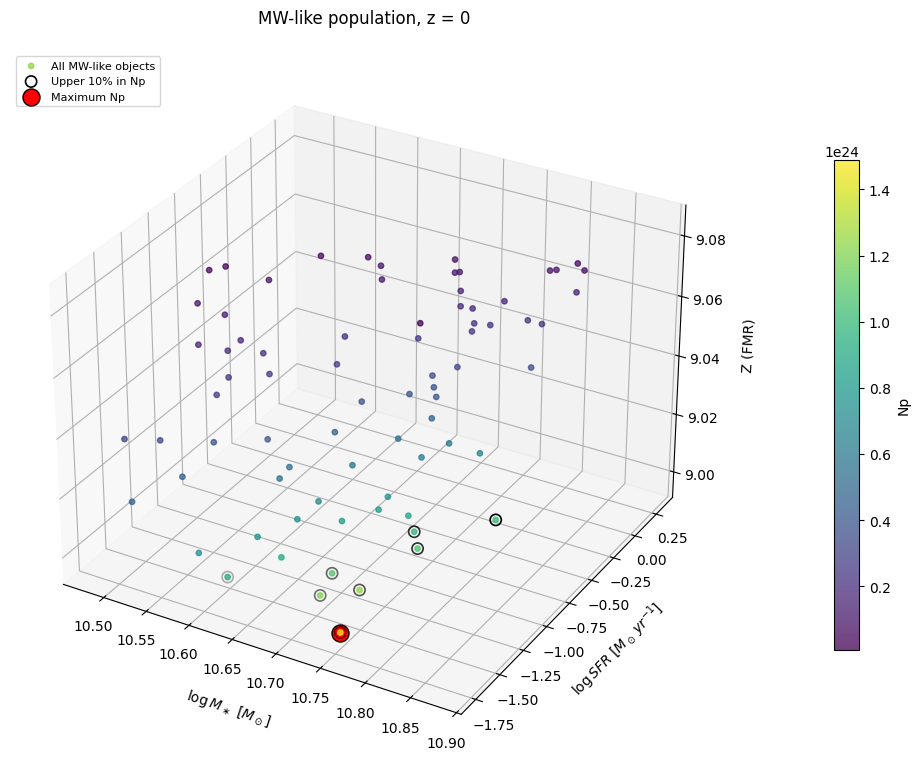


min(Np) = 7.935e+21
max(Np) = 1.489e+24
median(Np) = 3.101e+23

z = 1
Ukupan broj MW-like objekata = 208
Broj objekata u gornjih 10% = 21

MAX-Np OBJEKAT
logM       = 10.6692
logSFR     = -1.5614
Z          = 9.024080e+00
Np         = 7.164297e+23

GORNJIH 10% PO Np
min(Np) u top 10% = 3.413192e+23
max(Np) u top 10% = 7.164297e+23
median(Np) u top 10% = 4.069919e+23


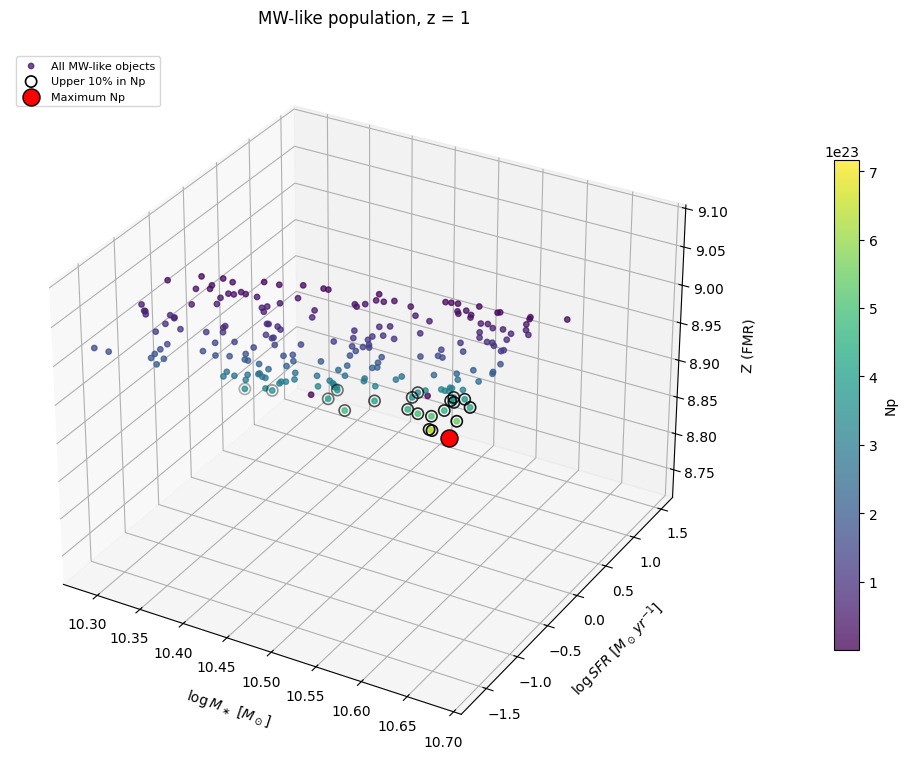


min(Np) = 1.310e+20
max(Np) = 7.164e+23
median(Np) = 1.344e+23

z = 2
Ukupan broj MW-like objekata = 268
Broj objekata u gornjih 10% = 27

MAX-Np OBJEKAT
logM       = 10.4594
logSFR     = -1.5140
Z          = 9.034599e+00
Np         = 2.447092e+23

GORNJIH 10% PO Np
min(Np) u top 10% = 1.396764e+23
max(Np) u top 10% = 2.447092e+23
median(Np) u top 10% = 1.675943e+23


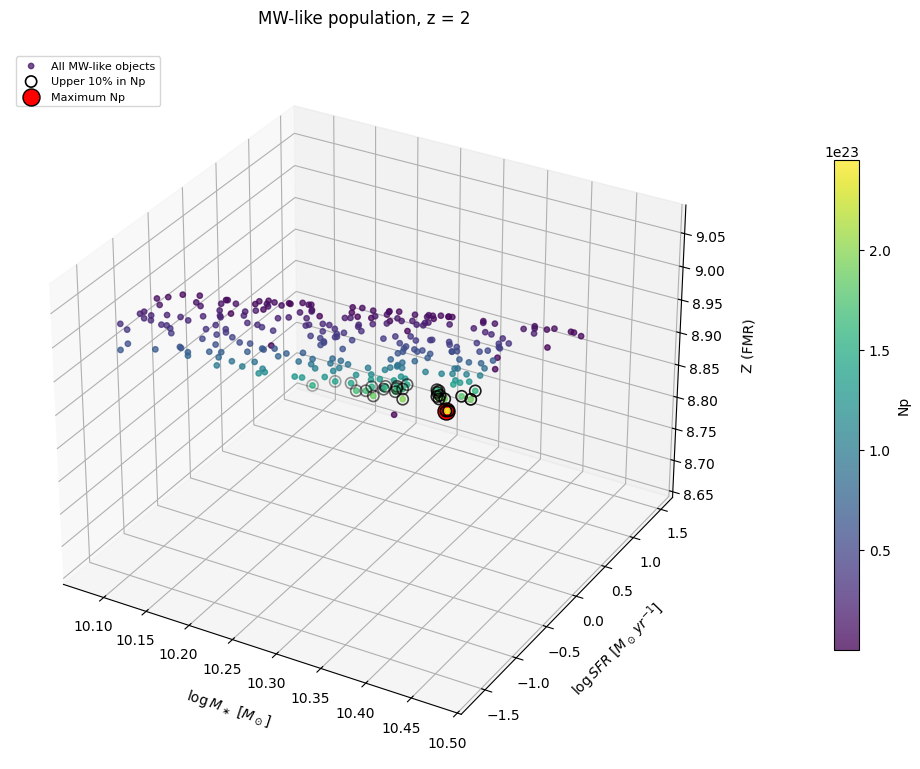


min(Np) = 6.764e+19
max(Np) = 2.447e+23
median(Np) = 4.021e+22

z = 3
Ukupan broj MW-like objekata = 1042
Broj objekata u gornjih 10% = 105

MAX-Np OBJEKAT
logM       = 10.1332
logSFR     = -2.0204
Z          = 8.976047e+00
Np         = 1.737824e+23

GORNJIH 10% PO Np
min(Np) u top 10% = 7.804003e+22
max(Np) u top 10% = 1.737824e+23
median(Np) u top 10% = 9.994951e+22


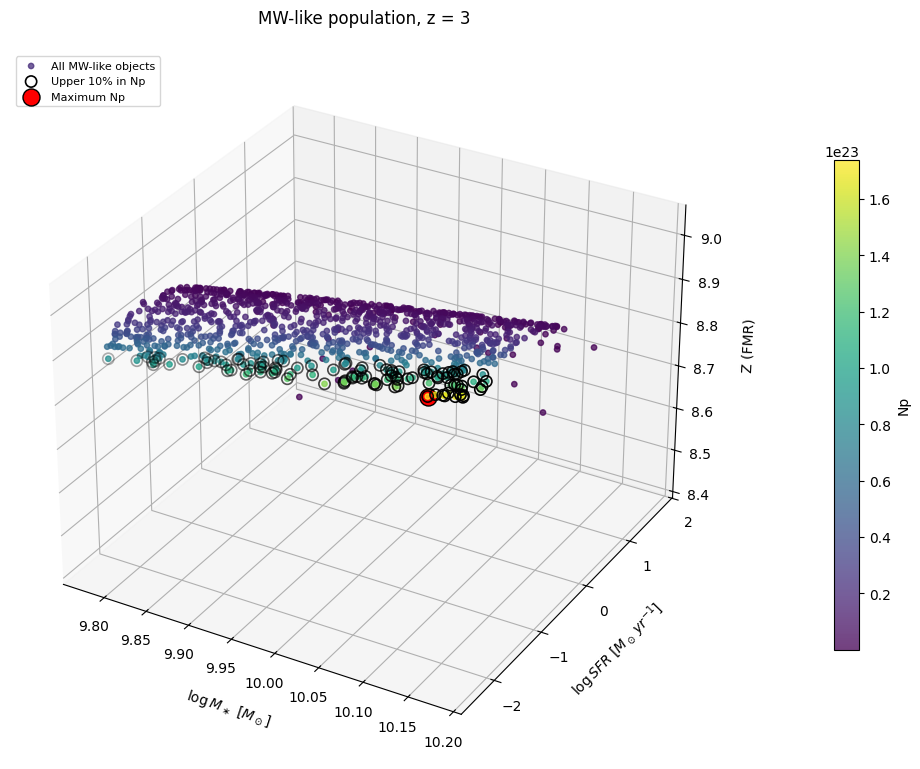


min(Np) = 9.078e+18
max(Np) = 1.738e+23
median(Np) = 1.677e+22


In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

alpha = 1.0

for z in range(4):

    df = pd.read_csv(
        f"MW_population_z{z}weighted.csv"
    )


    logM = df["logM"].values

    M = 10**logM


    logSFR = df["logSFR"].values

    SFR = 10**logSFR


    m = df["logM"] - 10
    s = df["logSFR"]

    def FMR(m, s):
        return (8.9+0.37*m-0.14*s-0.19*m**2+0.12*m*s-0.054*s**2)

    Z = FMR(m, s)


    Np = (
        M**2
        * Z**alpha
        / SFR
    )

    df["Np"] = Np


    max_index = np.argmax(Np)

    max_Np = Np[max_index]

    max_logM = logM[max_index]
    max_logSFR = logSFR[max_index]
    max_Z = Z[max_index]


    N = len(df)

    n_top10 = max(
        1,
        int(np.ceil(0.10 * N))
    )

    top10_indices = np.argsort(Np)[-n_top10:]

    top10_logM = logM[top10_indices]
    top10_logSFR = logSFR[top10_indices]
    top10_Z = Z[top10_indices]
    top10_Np = Np[top10_indices]


    print()
    
    print(f"z = {z}")

    print(f"Ukupan broj MW-like objekata = {N}")
    print(f"Broj objekata u gornjih 10% = {n_top10}")

    print()
    print("MAX-Np OBJEKAT")

    print(f"logM       = {max_logM:.4f}")
    print(f"logSFR     = {max_logSFR:.4f}")
    print(f"Z          = {max_Z:.6e}")
    print(f"Np         = {max_Np:.6e}")

    print()
    print("GORNJIH 10% PO Np")

    print(
        f"min(Np) u top 10% = "
        f"{top10_Np.min():.6e}"
    )

    print(
        f"max(Np) u top 10% = "
        f"{top10_Np.max():.6e}"
    )

    print(
        f"median(Np) u top 10% = "
        f"{np.median(top10_Np):.6e}"
    )


    fig = plt.figure(figsize=(10, 8))

    ax = fig.add_subplot(
        111,
        projection="3d"
    )


    scatter = ax.scatter(
        logM,
        logSFR,
        Z,
        c=Np,
        cmap="viridis",
        s=15,
        alpha=0.75,
        label="All MW-like objects"
    )



    ax.scatter(
        top10_logM,
        top10_logSFR,
        top10_Z,
        s=65,
        facecolors="none",
        edgecolors="black",
        linewidths=1.2,
        label="Upper 10% in Np"
    )



    ax.scatter(
        [max_logM],
        [max_logSFR],
        [max_Z],
        s=150,
        c="red",
        edgecolors="black",
        linewidths=1.0,
        label="Maximum Np"
    )



    ax.set_title(
        f"MW-like population, z = {z}",
        pad=20
    )

    ax.set_xlabel(
        r"$\log M_\ast\ [M_\odot]$",
        labelpad=10
    )

    ax.set_ylabel(
        r"$\log SFR\ [M_\odot\,yr^{-1}]$",
        labelpad=10
    )

    ax.set_zlabel(
        "Z (FMR)",
        labelpad=10
    )


    cbar = fig.colorbar(
        scatter,
        ax=ax,
        shrink=0.65,
        pad=0.12
    )

    cbar.set_label("Np")



    ax.legend(
        loc="upper left",
        fontsize=8
    )



    plt.tight_layout()
    plt.show()



    print()

    print(f"min(Np) = {Np.min():.3e}")
    print(f"max(Np) = {Np.max():.3e}")
    print(f"median(Np) = {np.median(Np):.3e}")